# 3D Strip Waveguide -- fdtdx Baseline

A true-3D FDTD baseline for the toolkit's silicon strip waveguide, run with
[**fdtdx**](https://github.com/ymahlau/fdtdx), a JAX-based 3D FDTD solver. The device is
a 500 × 220 nm Si core (n = 3.48) fully clad in SiO₂ (n = 1.44), driven at 1.35 µm in
its TE-like mode, with PML on all six faces.

This is the 3D counterpart of `notebooks/01_waveguide_baseline.ipynb`. That notebook
collapses the vertical confinement into a single effective index (2.7). Here the real
cross-section is on the grid, so the vertical mode profile, the true effective index
and the TE/TM distinction come out of the simulation instead of being assumed.

The notebook answers three questions:
1. Is the launched mode the TE-like mode, and what is the converged n_eff of this
   cross-section?
2. Does the propagating 3D field reproduce that n_eff, and does the straight guide
   carry its power without loss?
3. How close is the FDTD result once the grid holds exactly the nominal structure?

**Modeling assumption (deviates from the toolkit default):** real bulk indices on the
real 3D cross-section, not the 2D effective index. Materials are non-dispersive. See
the module docstring of `src/pic_toolkit/fdtdx_sim/waveguide_3d.py`.

**Kernel:** the `fdtdx` conda env (see `3d/README.md`).

## Contents
1. Setup
2. Geometry on the grid (res 20)
3. Mode check
4. Full 3D run at res 20
5. Matched-structure run at res 50
6. Design point and summary

**Do not use "Run All."** Each of the two 3D runs (Sections 4 and 5) takes several
minutes on a CPU. Work through the notebook section by section and look at each
checkpoint's plots before continuing.

## 1. Setup

fdtdx sets up a simulation differently from Meep. The differences that matter for the
physics in this notebook:

- **SI units.** Lengths are in metres and times in seconds. Resolution is still quoted
  in px/µm (grid spacing = 1/res µm) so it reads like the rest of the toolkit.
- **Objects plus placement constraints.** Objects (`SimulationVolume`,
  `UniformMaterialObject`, sources, detectors) are positioned by constraints such as
  `place_at_center`, and `place_objects` resolves them onto the grid.
- **Mode solving happens in `apply_params`.** The `ModePlaneSource` and every
  `ModeOverlapDetector` solve their cross-section with tidy3d's mode solver.
  `filter_pol="te"` keeps modes whose E field lies mainly along the first transverse
  axis, which is **y** for propagation along x: the `Ey`-dominant TE-like mode.
- **Fixed run length.** The run is one compiled XLA program with a fixed number of
  steps, with no decay-based stop condition. The run length is the pulse duration plus
  two group-delay transits of the cell (`wg3d.full_run_time`), so the pulse has fully
  crossed and left the cell when the run ends.
- **Staircased geometry.** Each cell is either core or cladding; there is no subpixel
  averaging. Object sizes and positions are rounded to whole cells, so the structure
  on the grid can differ from the nominal one. Section 2 shows exactly what the grid
  holds.
- **Precision and time step.** float32 fields, and dt = 0.99/√3 · Δx/c (Courant
  factor 0.99).

In [1]:
# Imports, the toolkit's plotting style, and where this notebook saves its design point.
from importlib.metadata import version
from pathlib import Path

import jax
import matplotlib.pyplot as plt
import numpy as np

import fdtdx
from pic_toolkit import style
from pic_toolkit.design_points import save_design_point
from pic_toolkit.fdtdx_sim import waveguide_3d as wg3d

# Importing fdtdx calls matplotlib.use("agg") (its video-plotting module does this at import
# time), which silently stops plt.show() from displaying figures in a notebook. Switch back
# to inline display right after the import.
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
style.apply_style()

DATA_DIR = Path.cwd().parent / "data"           # 3d/data (the notebook runs from 3d/notebooks)
DESIGN_POINT_PATH = DATA_DIR / "design_points" / "waveguide_3d.yaml"
UM = wg3d.UM
BASE = {"lx": 6.0, "sy": 3.0, "sz": 2.5}       # interior (non-PML) cell in um; 1 um PML is added on every face
K0 = 2 * np.pi / (wg3d.WL0_UM * UM)             # free-space wavenumber at 1.35 um, in 1/m
print(f"fdtdx {version('fdtdx')}, jax {jax.__version__}, backend: {jax.devices()[0].platform}")

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


fdtdx 0.6.0, jax 0.11.2, backend: cpu


## 2. Geometry on the grid (res 20)

The plots below show the permittivity that the FDTD grid actually holds, cell by cell
(nearest-neighbour, so the staircase is visible), on three orthogonal slices through
the core. Gray bands are the PML, the rose line is the source plane, and the crimson
dashed lines are the mode-overlap detector planes.

At res 20 (50 nm cells) the 500 nm width is exactly 10 cells, but the 220 nm height is
4.4 cells and rounds to **4 cells = 200 nm**. The grid therefore holds a slightly
thinner core than the nominal one. Section 4 judges the res-20 run against the
structure that is actually on the grid, and Section 5 removes the difference by
choosing a grid on which 500 × 220 nm is an exact number of cells.

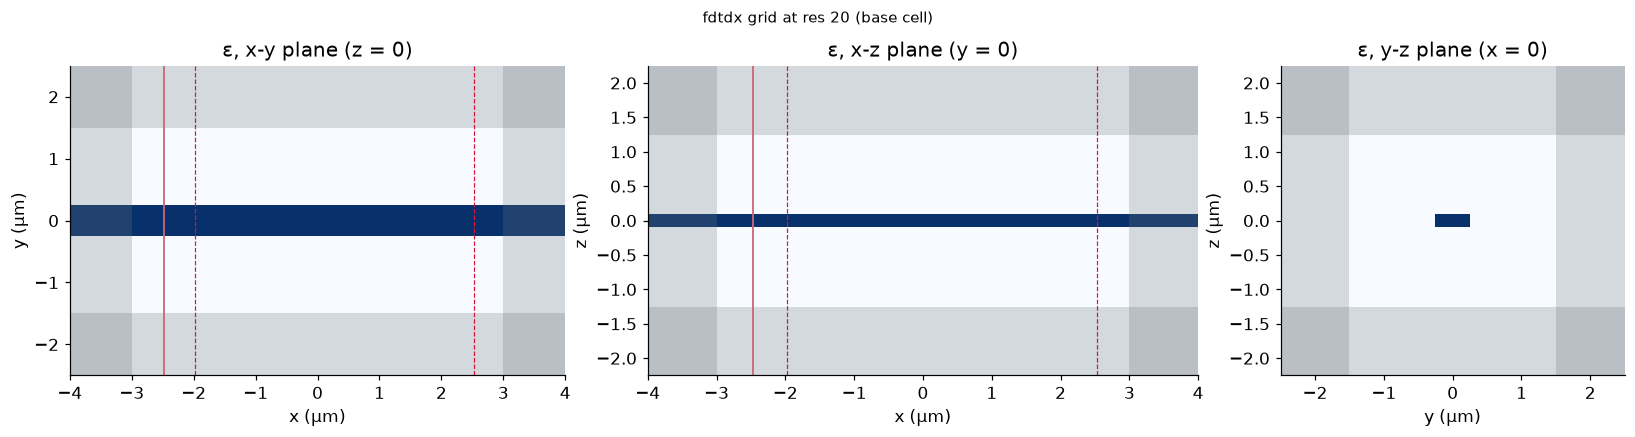

grid 160 x 100 x 90 = 1,440,000 cells at res 20 (incl. 1.0 um PML per face)
core on the grid: 10 x 4 cells = 500 x 200 nm (nominal 500 x 220); cladding cells either side: y (45, 45), z (43, 43)
time step 0.0953 fs, full run 267 fs = 2,802 steps


In [2]:
# Build (but do not run) the res-20 simulation, and plot what the grid holds.
def plot_geometry(arrays, objects, det_names, res, dpml, title):
    # x-y, x-z and y-z permittivity slices through the core, all with equal axis scales.
    # Source and detector planes are only drawn in the panels that contain x (in the y-z
    # panel they would cover the whole cross-section).
    eps = 1.0 / np.asarray(arrays.inv_permittivities[0])
    nx, ny, nz = eps.shape
    d = 1 / res
    X, Y, Z = nx * d, ny * d, nz * d
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [X / Y, X / Z, Y / Z]})
    panels = [(eps[:, :, nz // 2], X, Y, ("x", "y"), "x-y plane (z = 0)"),
              (eps[:, ny // 2, :], X, Z, ("x", "z"), "x-z plane (y = 0)"),
              (eps[nx // 2], Y, Z, ("y", "z"), "y-z plane (x = 0)")]
    for ax, (sl, w, h, (a, b), name) in zip(axes, panels):
        ax.imshow(sl.T, origin="lower", cmap=style.CMAP_PERMITTIVITY_BASELINE, aspect="equal",
                  interpolation="nearest", extent=[-w / 2, w / 2, -h / 2, h / 2])
        for rect in [(-w / 2, -h / 2, dpml, h), (w / 2 - dpml, -h / 2, dpml, h),
                     (-w / 2, -h / 2, w, dpml), (-w / 2, h / 2 - dpml, w, dpml)]:
            ax.add_patch(plt.Rectangle(rect[:2], rect[2], rect[3], color=style.COLOR_REFERENCE, alpha=0.25, lw=0))
        ax.set(title=f"ε, {name}", xlabel=f"{a} (µm)", ylabel=f"{b} (µm)")
        ax.grid(False)
    for ax in axes[:2]:
        ax.axvline((objects["source"].grid_slice[0].start + 0.5) * d - X / 2, color=style.COLOR_ROSE, lw=1.2)
        for n in det_names:
            ax.axvline((objects[n].grid_slice[0].start + 0.5) * d - X / 2, color=style.COLOR_ANNOTATION,
                       lw=0.8, ls="--")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    plt.show()


objects, arrays, params, config, det_names = wg3d.make_sim(20, **BASE, sim_time=wg3d.full_run_time(BASE["lx"]))
plot_geometry(arrays, objects, det_names, 20, wg3d.DPML_UM, "fdtdx grid at res 20 (base cell)")
g20 = wg3d.core_on_grid(arrays, 20)
nx, ny, nz = arrays.inv_permittivities.shape[1:]
print(f"grid {nx} x {ny} x {nz} = {nx * ny * nz:,} cells at res 20 (incl. {wg3d.DPML_UM} um PML per face)")
print(f"core on the grid: {g20['cells'][0]} x {g20['cells'][1]} cells = {g20['w_nm']:.0f} x {g20['h_nm']:.0f} nm "
      f"(nominal 500 x 220); cladding cells either side: y {g20['y_sides']}, z {g20['z_sides']}")
print(f"time step {config.time_step_duration * 1e15:.4f} fs, full run {config.time * 1e15:.0f} fs "
      f"= {config.time_steps_total:,} steps")

## 3. Mode check

Three questions, answered before any time stepping:

1. **Is the launched mode TE-like?** On the mode that the source and detectors actually
   solve on the FDTD grid, `|Ey|` should dominate `|Ez|`. The TM-like mode is solved too,
   for contrast. Plots use equal y/z scales and are cropped around the core.
2. **What is the converged n_eff?** The FDTD grid's own mode solve is not a converged
   reference: at res 20 the core is only 4 cells tall. The reference used throughout is
   **n_eff = 2.6460**, the MPB solution for the nominal 500 × 220 nm cross-section with
   subpixel averaging (converged: res 32 and 64 agree to 0.03 %). It is stored here as a
   constant; its convergence basis is recorded in `docs/simulation_settings_record.md`
   (section `fdtdx_sim/waveguide_3d.py`). As an independent check inside this notebook,
   the same tidy3d solver is run on fine cross-sections whose core edges fall exactly on
   cell boundaries. Without subpixel averaging it does not converge smoothly; it
   oscillates by a few tenths of a percent between resolutions, so it serves as a
   consistency band around the reference rather than as the reference itself.
3. **Is the mode symmetric?** The core is fully clad in oxide (no substrate), so every
   mode is mirror-symmetric in z. The printed *upper share* (fraction of |Ey|² + |Ez|²
   above the core's midplane) should be 0.5. The TM-like mode's dominant `Ez` is normal
   to the top and bottom faces and jumps by ε_core/ε_clad ≈ 5.8 across them, which the
   staggered grid samples unevenly. It therefore comes out lopsided on coarse grids, and
   the table shows this shrinking steadily as the grid is refined: a discretization
   effect, not a physical asymmetry.

TE-like: n_eff = 2.6159, max|Ey|/max|Ez| = 4.88, upper share = 0.499
TM-like: n_eff = 1.9295, max|Ey|/max|Ez| = 0.45, upper share = 0.571


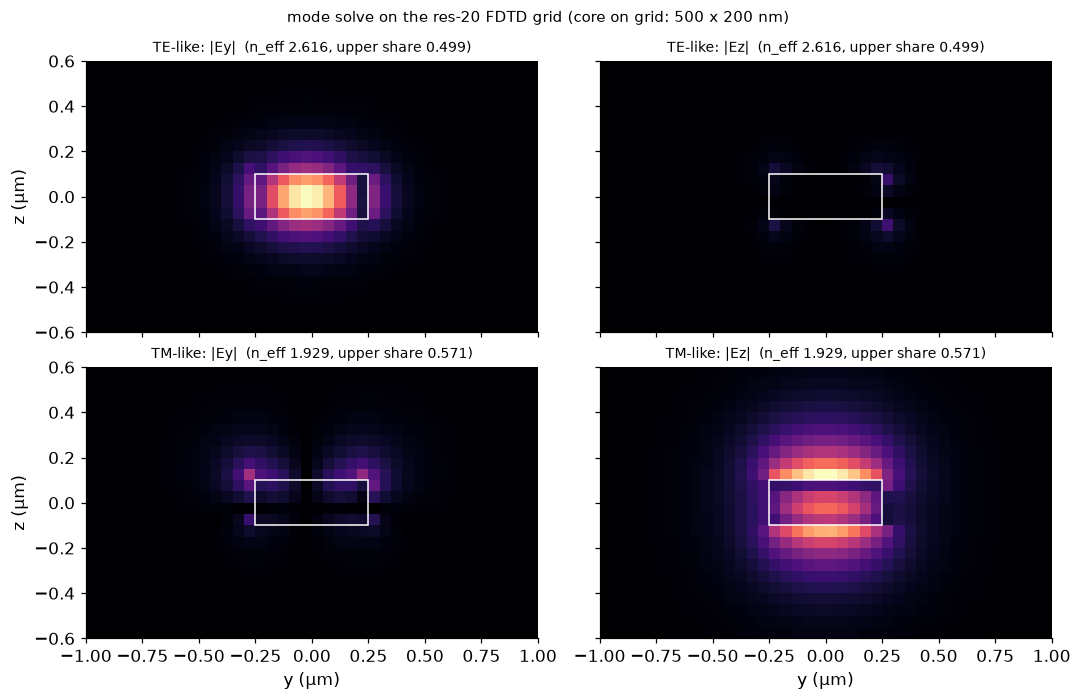

In [3]:
# (1) TE check on the FDTD grid: apply_params runs the mode solves for the source and detectors.
arrays_p, objects_p, _ = fdtdx.apply_params(arrays, objects, params, jax.random.PRNGKey(0))
det = objects_p[det_names[0]]
inv_eps_slice = arrays_p.inv_permittivities[:, *det.grid_slice]


def plot_modes(modes, res, title, window=(1.0, 0.6), core_nm=(500, 220)):
    # |Ey| and |Ez| of both modes on a shared color scale per mode, equal y/z scales, cropped
    # to +-window um around the core. Cells drawn as-is (nearest-neighbour). White box = core.
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey=True)
    for row, (label, m) in enumerate(modes.items()):
        ny, nz = m["Ey"].shape
        ext = [-ny / res / 2, ny / res / 2, -nz / res / 2, nz / res / 2]
        vmax = max(m["Ey"].max(), m["Ez"].max())
        for col, c in enumerate(("Ey", "Ez")):
            ax = axes[row, col]
            ax.imshow(m[c].T, origin="lower", cmap="magma", vmin=0, vmax=vmax, extent=ext, aspect="equal",
                      interpolation="nearest")
            ax.add_patch(plt.Rectangle((-core_nm[0] / 2000, -core_nm[1] / 2000), core_nm[0] / 1000,
                                       core_nm[1] / 1000, fill=False, ec="white", lw=1))
            ax.set_xlim(-window[0], window[0])
            ax.set_ylim(-window[1], window[1])
            ax.grid(False)
            ax.set_title(f"{label}: |{c}|  (n_eff {m['n_eff']:.3f}, upper share {m['upper_share']:.3f})", fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel("y (µm)")
    for ax in axes[:, 0]:
        ax.set_ylabel("z (µm)")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    plt.show()


modes = wg3d.solve_plane_modes(inv_eps_slice, arrays_p.inv_permeabilities, config.resolution)
for label, m in modes.items():
    print(f"{label}: n_eff = {m['n_eff']:.4f}, max|Ey|/max|Ez| = {m['Ey'].max() / m['Ez'].max():.2f}, "
          f"upper share = {m['upper_share']:.3f}")

N_EFF_GRID20 = modes["TE-like"]["n_eff"]
assert modes["TE-like"]["Ey"].max() > 3 * modes["TE-like"]["Ez"].max(), "filter_pol='te' did not give an Ey-dominant mode"
assert abs(float(np.real(det._mode_neff)) - N_EFF_GRID20) < 1e-4, "detector solved a different mode than expected"
plot_modes(modes, 20, f"mode solve on the res-20 FDTD grid (core on grid: {g20['w_nm']:.0f} x {g20['h_nm']:.0f} nm)",
           core_nm=(g20["w_nm"], g20["h_nm"]))

In [4]:
# (2) Converged reference n_eff, and the tidy3d consistency band on fine cross-sections with
#     grid-aligned core edges. (3) Mirror symmetry in z on every grid.
N_EFF_REF = 2.6460   # MPB, 500 x 220 nm, subpixel averaging, converged (basis: docs/simulation_settings_record.md)

fine = {r: wg3d.fine_grid_modes(r, BASE["sy"], BASE["sz"]) for r in (50, 100, 150)}
ref_tidy3d = {r: m["TE-like"]["n_eff"] for r, m in fine.items()}

print("mirror balance in z (upper share of |Ey|^2+|Ez|^2; 0.5 = symmetric):")
print(f"{'grid':>26} {'TE-like':>9} {'TM-like':>9}")
print(f"{'res 20 FDTD grid (200 nm)':>26} {modes['TE-like']['upper_share']:>9.3f} {modes['TM-like']['upper_share']:>9.3f}")
for r, m in fine.items():
    print(f"{f'res {r} fine grid (220 nm)':>26} {m['TE-like']['upper_share']:>9.3f} {m['TM-like']['upper_share']:>9.3f}")

print(f"\nreference (converged MPB): n_eff = {N_EFF_REF:.4f}")
for r, n in ref_tidy3d.items():
    print(f"tidy3d res {r:>3} (no subpixel averaging): n_eff = {n:.4f}  ({100 * (n / N_EFF_REF - 1):+.2f}% vs reference)")
# Consistency band: the two finer tidy3d solves must sit within 0.5% of the reference.
assert all(abs(ref_tidy3d[r] / N_EFF_REF - 1) < 0.005 for r in (100, 150)), "tidy3d and the reference disagree by >0.5%"
print(f"FDTD-grid (res 20) mode solve gave {N_EFF_GRID20:.4f} ({100 * (N_EFF_GRID20 / N_EFF_REF - 1):+.1f}%)")
del arrays, arrays_p, objects, objects_p   # release the res-20 setup; Section 4 builds its own

mirror balance in z (upper share of |Ey|^2+|Ez|^2; 0.5 = symmetric):
                      grid   TE-like   TM-like
 res 20 FDTD grid (200 nm)     0.499     0.571
 res 50 fine grid (220 nm)     0.499     0.511
res 100 fine grid (220 nm)     0.500     0.505
res 150 fine grid (220 nm)     0.500     0.504

reference (converged MPB): n_eff = 2.6460
tidy3d res  50 (no subpixel averaging): n_eff = 2.6308  (-0.57% vs reference)
tidy3d res 100 (no subpixel averaging): n_eff = 2.6517  (+0.21% vs reference)
tidy3d res 150 (no subpixel averaging): n_eff = 2.6429  (-0.12% vs reference)
FDTD-grid (res 20) mode solve gave 2.6159 (-1.1%)


> **STOP -- check the mode.** The TE-like row should show a strong `|Ey|` lobe filling
> the core with weak `|Ez|`. The fine-grid tidy3d values should sit within a few tenths
> of a percent of the reference. If they don't, the reference itself is in question.

## 4. Full 3D run at res 20

The run uses the base cell (6 × 3 × 2.5 µm interior) at res 20, where the core sits
**exactly centered** on the grid (asserted below). fdtdx rounds object positions to
whole cells, so on this cell some other resolutions (25 and 30 px/µm) put the core one
cell off-center, which would make the simulated structure asymmetric.

Eight mode-overlap detectors are spread along the guide, plus `Ey`/`Ez` phasor planes
for the field pictures. Checks:

1. **Transmission:** |α_i / α_0|² across the 8 detectors should stay at 1, since the
   guide is straight and lossless.
2. **n_eff from the propagating field**, by two independent methods:
   - the phase of the mode-overlap coefficients across the 8 detectors. fdtdx's
     overlap coefficients use an `exp(-iωt)` convention, so the forward-wave phase
     *decreases* with x. The detectors are ~0.6 µm apart, so the 2π ambiguity is
     resolved with the reference n_eff, and the fit residual shows whether that worked.
   - the unwrapped phase slope of the dense `Ey` phasor along the core axis. It has no
     ambiguity: about 0.6 rad per cell at res 20.

   Both methods use positions taken from the detectors' actual grid indices, not the
   requested coordinates.

   **Which reference?** The res-20 grid holds a 500 × 200 nm core, so the FDTD result is
   judged against the converged n_eff of *that* structure, computed with tidy3d on a fine
   grid that reproduces the staircase exactly. The nominal 220 nm value (2.6460) is
   printed too, but agreement with it at res 20 would be a coincidence: the thinner core
   lowers n_eff while the grid's numerical dispersion raises it. The tolerance against
   the on-grid structure is 4 % (basis in `docs/simulation_settings_record.md`).
3. **Field pictures** on the x-y mid-plane and the y-z cross-section.

> **STOP -- the next cell runs the full 3D FDTD simulation** (several minutes on a CPU).

In [5]:
# Full run at res 20 with 8 mode-overlap detectors and the two phasor planes.
RUN_RES, RUN_LX, N_DET = 20, BASE["lx"], 8
arrays, objects, config, det_names, timing = wg3d.build_and_run(RUN_RES, RUN_LX, BASE["sy"], BASE["sz"],
                                                               sim_time=wg3d.full_run_time(RUN_LX),
                                                               n_det=N_DET, field_slices=True)
g_run = wg3d.core_on_grid(arrays, RUN_RES)
assert wg3d.is_centered(g_run), "core is not exactly centered on the res-20 grid"
print(f"{timing['time_steps']:,} steps, run {timing['t_run_s'] / 60:.1f} min; "
      f"core on this grid: {g_run['w_nm']:.0f} x {g_run['h_nm']:.0f} nm, centered")

2,802 steps, run 3.2 min; core on this grid: 500 x 200 nm, centered


In [6]:
# 1) Transmission and 2a) n_eff from the mode-overlap coefficients along the guide.
def neff_from_detectors(objects, arrays, det_names, dx):
    # Forward-wave phase of the overlap coefficients, unwrapped against the reference n_eff,
    # then a straight-line fit of phase vs the detectors' actual grid positions.
    alphas = np.array([complex(objects[n].compute_overlap(arrays.detector_states[n])) for n in det_names])
    x_det = np.array([objects[n].grid_slice[0].start for n in det_names]) * dx
    d = -np.angle(alphas)                       # exp(-i w t) convention -> forward-wave phase falls with x
    d = d - d[0]
    m = np.round((N_EFF_REF * K0 * (x_det - x_det[0]) - d) / (2 * np.pi))
    phc = d + 2 * np.pi * m
    p = np.polyfit(x_det, phc, 1)
    T = np.abs(alphas / alphas[0]) ** 2
    return T, p[0] / K0, float(np.std(phc - np.polyval(p, x_det)))


def neff_from_line(objects, arrays, dx, skip_start_um, skip_end_um):
    # 2b) Unwrapped phase slope of the Ey phasor along the core axis (x-y mid-plane, central
    # y rows), keeping clear of the source and of the far end of the cell.
    xy = np.asarray(arrays.detector_states["phasor_xy"]["phasor"])[0, 0, 0, :, :, 0]
    ny_ = xy.shape[1]
    line = xy[:, ny_ // 2] if ny_ % 2 else xy[:, ny_ // 2 - 1: ny_ // 2 + 1].mean(axis=1)
    x_line = (objects["phasor_xy"].grid_slice[0].start + np.arange(line.size)) * dx
    x_src = objects["source"].grid_slice[0].start * dx
    sel = (x_line > x_src + skip_start_um * UM) & (x_line < x_line[-1] - skip_end_um * UM)
    ph = np.unwrap(np.angle(line[sel]))
    p = np.polyfit(x_line[sel], ph, 1)
    return xy, abs(p[0]) / K0, float(np.std(ph - np.polyval(p, x_line[sel])))


dx = UM / RUN_RES
T_det, N_EFF_DET, resid_det = neff_from_detectors(objects, arrays, det_names, dx)
xy, N_EFF_LINE, resid_line = neff_from_line(objects, arrays, dx, 1.0, 0.5)

# Reference for the structure actually on this grid: tidy3d on a fine grid that is an integer
# multiple of RUN_RES (>= 100 px/um), so the staircased core is reproduced exactly.
fine_res = RUN_RES * int(np.ceil(100 / RUN_RES))
N_EFF_ACTUAL = wg3d.fine_grid_modes(fine_res, BASE["sy"], BASE["sz"],
                                    g_run["w_nm"] / 1000, g_run["h_nm"] / 1000)["TE-like"]["n_eff"]

print("transmission |a_i/a_0|^2:", np.round(T_det, 4))
print(f"n_eff (8 overlap detectors) = {N_EFF_DET:.4f}   fit residual {resid_det:.3f} rad")
print(f"n_eff (dense Ey line)       = {N_EFF_LINE:.4f}   fit residual {resid_line:.4f} rad")
print(f"reference for the {g_run['w_nm']:.0f} x {g_run['h_nm']:.0f} nm core on this grid (tidy3d res {fine_res}) "
      f"= {N_EFF_ACTUAL:.4f} -> FDTD excess {100 * (N_EFF_LINE / N_EFF_ACTUAL - 1):+.2f}%   <- the meaningful comparison")
print(f"nominal 500 x 220 nm reference = {N_EFF_REF:.4f} -> difference {100 * (N_EFF_LINE / N_EFF_REF - 1):+.2f}% "
      f"(different structure at res {RUN_RES}; Section 5 compares like with like)")

transmission |a_i/a_0|^2: [1. 1. 1. 1. 1. 1. 1. 1.]
n_eff (8 overlap detectors) = 2.6550   fit residual 0.000 rad
n_eff (dense Ey line)       = 2.6550   fit residual 0.0000 rad
reference for the 500 x 200 nm core on this grid (tidy3d res 100) = 2.5802 -> FDTD excess +2.90%   <- the meaningful comparison
nominal 500 x 220 nm reference = 2.6460 -> difference +0.34% (different structure at res 20; Section 5 compares like with like)


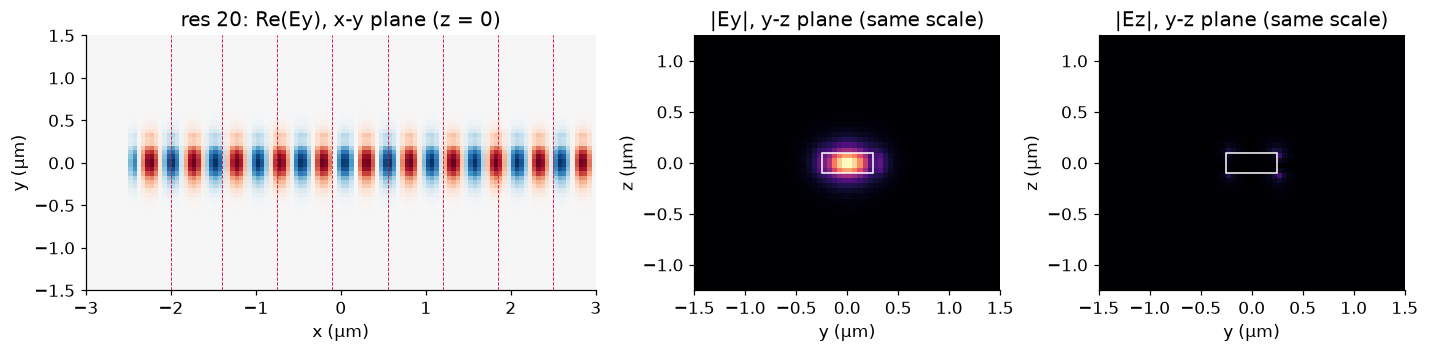

In [7]:
# 3) Field pictures: Re(Ey) on the x-y mid-plane; |Ey| and |Ez| on the y-z cross-section.
def plot_fields(xy, yz, lx, sy, sz, core_nm, title, det_x_um=()):
    nxl, nyl = xy.shape
    fig = plt.figure(figsize=(13, 3.8))
    gs = fig.add_gridspec(1, 3, width_ratios=[nxl / nyl, sy / sz, sy / sz])
    ax = fig.add_subplot(gs[0])
    v = np.abs(xy).max()
    ax.imshow(np.real(xy).T, origin="lower", cmap=style.CMAP_FIELD, vmin=-v, vmax=v, aspect="equal",
              extent=[-lx / 2, lx / 2, -sy / 2, sy / 2])
    for xd in det_x_um:
        ax.axvline(xd, color=style.COLOR_ANNOTATION, lw=0.6, ls="--")
    ax.set(title=f"{title}: Re(Ey), x-y plane (z = 0)", xlabel="x (µm)", ylabel="y (µm)")
    ax.grid(False)
    v = max(np.abs(yz[0]).max(), np.abs(yz[1]).max())
    for k, name in enumerate(("Ey", "Ez")):
        ax = fig.add_subplot(gs[k + 1])
        ax.imshow(np.abs(yz[k]).T, origin="lower", cmap="magma", vmin=0, vmax=v, aspect="equal",
                  extent=[-sy / 2, sy / 2, -sz / 2, sz / 2])
        ax.add_patch(plt.Rectangle((-core_nm[0] / 2000, -core_nm[1] / 2000), core_nm[0] / 1000,
                                   core_nm[1] / 1000, fill=False, ec="white", lw=1))
        ax.set(title=f"|{name}|, y-z plane (same scale)", xlabel="y (µm)", ylabel="z (µm)")
        ax.grid(False)
    fig.tight_layout()
    plt.show()


yz = np.asarray(arrays.detector_states["phasor_yz"]["phasor"])[0, 0, :, 0]   # (2, ny, nz): Ey, Ez
x0_um = objects["phasor_xy"].grid_slice[0].start / RUN_RES
plot_fields(xy, yz, RUN_LX, BASE["sy"], BASE["sz"], (g_run["w_nm"], g_run["h_nm"]), f"res {RUN_RES}",
            det_x_um=[objects[n].grid_slice[0].start / RUN_RES - x0_um - RUN_LX / 2 for n in det_names])

T_DEV20 = float(np.abs(1 - T_det).max())
assert T_DEV20 < 0.03, "transmission along the guide deviates from 1 by more than 3%"
assert resid_det < 0.1 and abs(N_EFF_DET / N_EFF_LINE - 1) < 1e-3, "detector and line n_eff methods disagree"
assert abs(N_EFF_LINE / N_EFF_ACTUAL - 1) < 0.04, "FDTD n_eff differs from its structure's reference by more than 4%"

> **STOP -- check the fields.** `Re(Ey)` should show clean, evenly spaced wavefronts
> confined to the core, with no standing-wave pattern (a straight lossless guide reflects
> nothing). `|Ey|` should dominate `|Ez|` on the cross-section.

## 5. Matched-structure run at res 50

At res 20 the grid holds a 500 × 200 nm core, so the FDTD result cannot be compared
directly with the nominal reference. At res 50 (20 nm cells), 500 × 220 nm is exactly
**25 × 11 cells**, so the grid holds the nominal structure with no staircase error:

- **Compact cell, sized for symmetry.** The interior is 3.0 × 2.02 × 1.62 µm with
  0.5 µm PML. The 2.02 / 1.62 µm sizes make the total cell counts odd (151 × 131), so the
  25 × 11-cell core sits **exactly** centered. Even counts (e.g. 2.0 × 1.6 µm) would put
  the core one cell off-center in y and z.
- **Same analysis as Section 4:** transmission along the guide, n_eff by both methods
  against the reference 2.6460 (now the right reference, since the grid holds exactly
  500 × 220 nm), mode symmetry and field pictures. What remains is the FDTD grid's own
  numerical dispersion. Tolerance: 2.5 % (basis in `docs/simulation_settings_record.md`).

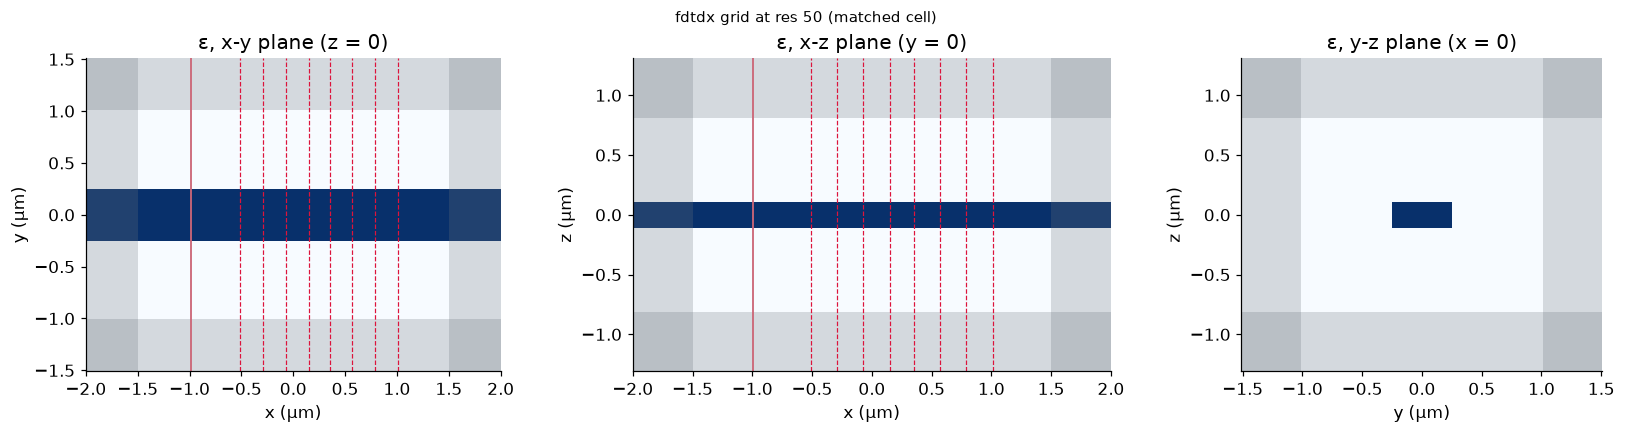

core on the grid: 25 x 11 cells = 500 x 220 nm; cladding cells either side: y (63, 63), z (60, 60)


In [8]:
# Matched configuration: build (no run) and confirm the core is exactly 25 x 11 cells and centered.
MATCH = {"res": 50, "lx": 3.0, "sy": 2.02, "sz": 1.62, "dpml": 0.5}
R50 = MATCH["res"]
del arrays, objects                      # release the res-20 run before building the larger grid
jax.clear_caches()

objs50, arr50, _, _, dets50 = wg3d.make_sim(R50, MATCH["lx"], MATCH["sy"], MATCH["sz"], sim_time=1e-15,
                                             n_det=8, dpml=MATCH["dpml"])
plot_geometry(arr50, objs50, dets50, R50, MATCH["dpml"], "fdtdx grid at res 50 (matched cell)")
g50 = wg3d.core_on_grid(arr50, R50)
print(f"core on the grid: {g50['cells'][0]} x {g50['cells'][1]} cells = {g50['w_nm']:.0f} x {g50['h_nm']:.0f} nm; "
      f"cladding cells either side: y {g50['y_sides']}, z {g50['z_sides']}")
assert g50["cells"] == (25, 11), "core is not exactly 25 x 11 cells"
assert wg3d.is_centered(g50), "core is not centered"
del objs50, arr50

> **STOP -- the next cell runs the res-50 3D simulation** (~4 M cells; the longest step
> in this notebook, on the order of ten minutes on a CPU).

In [9]:
# Full run on the matched grid: 8 mode-overlap detectors + phasor planes, as in Section 4.
arrays, objects, config, det_names, timing50 = wg3d.build_and_run(
    R50, MATCH["lx"], MATCH["sy"], MATCH["sz"], sim_time=wg3d.full_run_time(MATCH["lx"], dpml=MATCH["dpml"]),
    n_det=8, field_slices=True, dpml=MATCH["dpml"])
print(f"{timing50['time_steps']:,} steps, run {timing50['t_run_s'] / 60:.1f} min")

4,067 steps, run 11.6 min


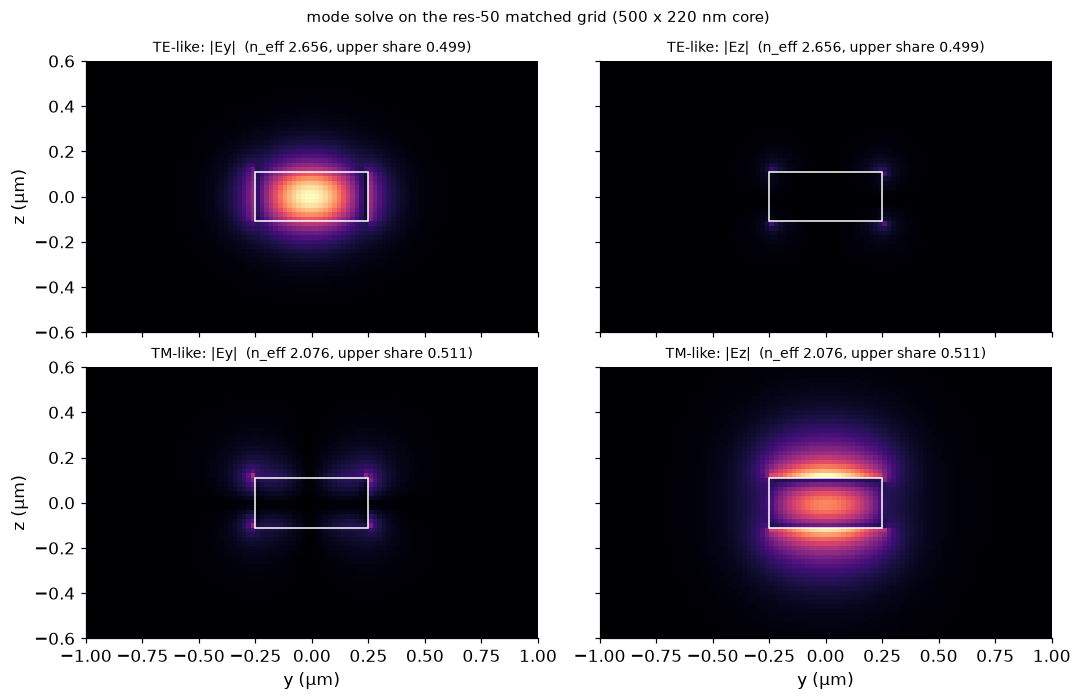

transmission |a_i/a_0|^2: [1. 1. 1. 1. 1. 1. 1. 1.]
TE-like: grid mode n_eff 2.6557, upper share 0.499
TM-like: grid mode n_eff 2.0762, upper share 0.511
n_eff (8 detectors) = 2.6621 (resid 0.000 rad), dense line = 2.6621 (resid 0.0000 rad)
reference (500 x 220 nm) = 2.6460 -> FDTD excess +0.61%


In [10]:
# Modes on the matched grid (equal y/z scales), transmission, and n_eff by both methods.
det = objects[det_names[0]]
modes50 = wg3d.solve_plane_modes(arrays.inv_permittivities[:, *det.grid_slice], arrays.inv_permeabilities,
                                 config.resolution)
plot_modes(modes50, R50, "mode solve on the res-50 matched grid (500 x 220 nm core)")

dx = UM / R50
T50, N_EFF_DET50, resid_det50 = neff_from_detectors(objects, arrays, det_names, dx)
xy50, N_EFF_LINE50, resid_line50 = neff_from_line(objects, arrays, dx, 0.5, 0.25)

print(f"transmission |a_i/a_0|^2: {np.round(T50, 4)}")
for label, mm in modes50.items():
    print(f"{label}: grid mode n_eff {mm['n_eff']:.4f}, upper share {mm['upper_share']:.3f}")
print(f"n_eff (8 detectors) = {N_EFF_DET50:.4f} (resid {resid_det50:.3f} rad), "
      f"dense line = {N_EFF_LINE50:.4f} (resid {resid_line50:.4f} rad)")
print(f"reference (500 x 220 nm) = {N_EFF_REF:.4f} -> FDTD excess {100 * (N_EFF_LINE50 / N_EFF_REF - 1):+.2f}%")

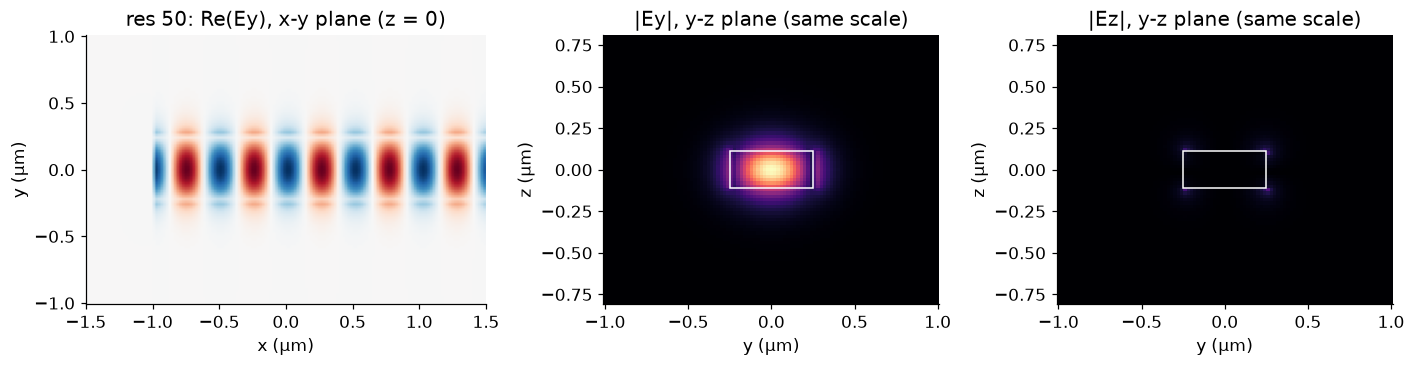

In [11]:
# Field pictures on the matched grid, equal axis scales, and the res-50 checks.
yz50 = np.asarray(arrays.detector_states["phasor_yz"]["phasor"])[0, 0, :, 0]
plot_fields(xy50, yz50, MATCH["lx"], MATCH["sy"], MATCH["sz"], (500, 220), "res 50")

T_DEV50 = float(np.abs(1 - T50).max())
assert T_DEV50 < 0.03, "transmission along the guide deviates from 1 by more than 3%"
assert abs(N_EFF_DET50 / N_EFF_LINE50 - 1) < 1e-3, "detector and line n_eff methods disagree"
assert abs(N_EFF_LINE50 / N_EFF_REF - 1) < 0.025, "FDTD n_eff differs from the converged reference by more than 2.5%"
assert abs(modes50["TE-like"]["upper_share"] - 0.5) < 0.01, "TE-like mode is not z-symmetric"

> **STOP -- check the matched-grid fields and numbers.** The wavefronts should again be
> clean, the TE-like mode z-symmetric (upper share 0.500), and the FDTD n_eff within a
> fraction of a percent of the reference. The next section saves the design point.

## 6. Design point and summary

The record follows the toolkit's design-point schema
(`component / parameters / measured / provenance / validation / rationale`). It is
saved to `3d/data/design_points/waveguide_3d.yaml`, separate from the 2D track's
`data/design_points/`, because its numbers belong to a different model (real 3D
cross-section, bulk indices) and must not be mixed with the 2D effective-index
components.

In [12]:
# Design point: parameters, measured n_eff on both grids, provenance and validation.
record = {
    "component": "waveguide_3d",
    "parameters": {
        "wg_width_um": wg3d.WG_WIDTH_UM, "wg_height_um": wg3d.WG_HEIGHT_UM,
        "core_index": wg3d.CORE_INDEX, "clad_index": wg3d.CLAD_INDEX,
        "wavelength_um": wg3d.WL0_UM, "polarization": "TE-like (Ey-dominant), filter_pol='te'",
    },
    "measured": {
        "n_eff_reference_mpb": N_EFF_REF,
        "n_eff_tidy3d_fine": {int(r): float(n) for r, n in ref_tidy3d.items()},
        "res20": {"core_on_grid_nm": [float(g_run["w_nm"]), float(g_run["h_nm"])],
                  "n_eff_fdtd": float(N_EFF_LINE), "n_eff_reference_on_grid_core": float(N_EFF_ACTUAL),
                  "excess_vs_on_grid_core_pct": float(100 * (N_EFF_LINE / N_EFF_ACTUAL - 1)),
                  "transmission_max_dev": T_DEV20},
        "res50_matched": {"cell_um": [MATCH["lx"], MATCH["sy"], MATCH["sz"]], "dpml_um": MATCH["dpml"],
                          "n_eff_fdtd": float(N_EFF_LINE50),
                          "excess_vs_reference_pct": float(100 * (N_EFF_LINE50 / N_EFF_REF - 1)),
                          "transmission_max_dev": T_DEV50,
                          "grid_mode_n_eff": {k: float(mm["n_eff"]) for k, mm in modes50.items()},
                          "upper_share": {k: float(mm["upper_share"]) for k, mm in modes50.items()}},
    },
    "provenance": {"method": "3D FDTD, mode-overlap phase + dense Ey phasor phase slope",
                   "solver": f"fdtdx {version('fdtdx')} (jax {jax.__version__}, {jax.devices()[0].platform})",
                   "module": "pic_toolkit.fdtdx_sim.waveguide_3d", "steps_res50": int(timing50["time_steps"])},
    "validation": {"te_like_ey_over_ez_res20": float(modes["TE-like"]["Ey"].max() / modes["TE-like"]["Ez"].max()),
                   "detector_vs_line_n_eff_rel_diff_res50": float(abs(N_EFF_DET50 / N_EFF_LINE50 - 1)),
                   "tolerances": {"transmission_dev": 0.03, "n_eff_vs_on_grid_core_res20": 0.04,
                                  "n_eff_vs_reference_res50": 0.025},
                   "passed": True},
    "rationale": ("Res 50 is the matched grid: 500 x 220 nm is exactly 25 x 11 cells and the core is exactly "
                  "centered, so the FDTD n_eff compares directly with the converged reference; the remaining "
                  "excess is the FDTD grid's numerical dispersion. Res 20 holds a 500 x 200 nm core and is "
                  "judged against that structure's own reference."),
}
save_design_point(DESIGN_POINT_PATH, record)
print("saved", DESIGN_POINT_PATH)

print(f"\n{'':>34} {'res 20':>10} {'res 50 (matched)':>17}")
print(f"{'core on the grid (nm)':>34} {g_run['w_nm']:>4.0f} x {g_run['h_nm']:<3.0f} {'500 x 220':>17}")
print(f"{'FDTD n_eff':>34} {N_EFF_LINE:>10.4f} {N_EFF_LINE50:>17.4f}")
print(f"{'reference for that structure':>34} {N_EFF_ACTUAL:>10.4f} {N_EFF_REF:>17.4f}")
print(f"{'FDTD excess':>34} {100 * (N_EFF_LINE / N_EFF_ACTUAL - 1):>+9.2f}% {100 * (N_EFF_LINE50 / N_EFF_REF - 1):>+16.2f}%")
print(f"{'max |1 - T| along the guide':>34} {T_DEV20:>10.1e} {T_DEV50:>17.1e}")

saved /home/yuma/meep-course/photonics-simulation-toolkit/3d/data/design_points/waveguide_3d.yaml

                                       res 20  res 50 (matched)
             core on the grid (nm)  500 x 200         500 x 220
                        FDTD n_eff     2.6550            2.6621
      reference for that structure     2.5802            2.6460
                       FDTD excess     +2.90%            +0.61%
       max |1 - T| along the guide    1.6e-05           2.6e-06


**What the numbers mean.**

- **The launched mode is the TE-like mode.** `filter_pol="te"` gives the `Ey`-dominant
  mode at the source and every detector, and the straight guide carries it with no
  measurable loss (|1 − T| at the 10⁻⁴ level or below on both grids).
- **Compare like with like.** At res 20 the staircase holds a 500 × 200 nm core. Its
  FDTD n_eff sits a few percent above the reference *for that core*, which is the
  numerical dispersion of a 50 nm grid (only ~8–10 cells per guided wavelength). Any closeness
  to the nominal 2.6460 at res 20 is two errors cancelling, not accuracy.
- **On the matched grid the FDTD is accurate to well under a percent.** At res 50 the
  grid holds exactly 500 × 220 nm, and the FDTD n_eff lands a fraction of a percent above
  the converged reference. That residual is still numerical dispersion, and for any
  interferometric 3D device it matters: accumulated phase over tens of µm is
  percent-level, so such a device's phase needs calibrating, not just simulating.
- **Mode symmetry.** The TE-like mode is z-symmetric on every grid. The TM-like mode's
  lopsidedness on coarse grids is a discretization effect of its normal `Ez` component,
  and it shrinks steadily with resolution (Section 3 table).